In [23]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (mean_absolute_error, r2_score,
                             accuracy_score, confusion_matrix,
                             ConfusionMatrixDisplay)
import matplotlib.pyplot as plt
import plotly.express as px

print("Imports OK")

Imports OK


Part 1 — Explore & Split 
Exercise 1.1 — Know your data 

In [24]:
# ---------- Exercise 1.1 - Know your data (2 marks) ----------
from pathlib import Path
import pandas as pd

possible_paths = [
    Path.cwd() / "week10_students.csv",
    Path(r"C:\Users\done_well\Desktop\week10_bienfaitNtagayisha\week10_students.csv"),
    Path("/mnt/c/Users/done_well/Desktop/week10_bienfaitNtagayisha/week10_students.csv"),
]

csv_path = next((p for p in possible_paths if p.exists()), possible_paths[0])
df = pd.read_csv(csv_path)

print("Shape:", df.shape)
print("\nCorrelation of each feature with score:")
print(
    df[["quiz_avg", "assignments_avg", "attendance_pct", "score"]]
    .corr()["score"]
    .sort_values(ascending=False)
)

# COMMENT — Which feature looks most useful?
# quiz_avg has the highest correlation with score, so it is the most useful
# single predictor of a student's exam result. assignments_avg is a close
# second, while attendance_pct has the weakest (still positive) correlation.

Shape: (150, 9)

Correlation of each feature with score:
score              1.000000
quiz_avg           0.800726
assignments_avg    0.535983
attendance_pct     0.238118
Name: score, dtype: float64


Exercise 1.2 — Frame & split (3 marks)
Q: (a) Build x (three features) and y (score). (b) train_test_split(x, y, test_size=0.25, random_state=42). (c) Print both set sizes and explain in a comment why 25% of students are hidden from the model.

In [25]:
from sklearn.model_selection import train_test_split

 # ---------- Exercise 1.2 - Frame & split (3 marks) ----------
X = df[["quiz_avg", "assignments_avg", "attendance_pct"]]
y = df["score"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

print("Train size:", len(X_train))
print("Test size :", len(X_test))

# COMMENT — Why hide 25% of students from the model?
# We set aside 25% of the data (38 students) as a TEST set. The model never
# sees these rows during training. This lets us measure how well the model
# generalises to students it has never encountered — the real-world scenario.
# If we evaluated on the training data, the model could simply memorize the
# answers and look far more accurate than it truly is.

Train size: 112
Test size : 38


Part 2 — Regression: Predict the Score (10 marks)
Exercise 2.1 — Train & read the model (3 marks)
 

In [26]:
from sklearn.linear_model import LinearRegression
# ---------- Exercise 2.1 - Train & read the model (3 marks) ----------
model = LinearRegression()
model.fit(X_train, y_train)

print("Intercept:", round(model.intercept_, 4))
for name, coef in zip(X.columns, model.coef_):
    print(f"{name:>15}: {coef:.4f}")

# COMMENT — One extra quiz point = how many exam points?
# The quiz_avg coefficient estimates the change in exam score associated
# with a one-point increase in quiz_avg, holding the other features constant.
# ---------- Exercise 2.1 - Train & read the model (3 marks) ----------
model = LinearRegression()
model.fit(X_train, y_train)

print("Intercept:", round(model.intercept_, 4))
for name, coef in zip(X.columns, model.coef_):
    print(f"{name:>15}: {coef:.4f}")

# COMMENT — One extra quiz point = how many exam points?
# The quiz_avg coefficient answers this exactly: holding assignments and
# attendance constant, each additional quiz point is associated with that
# many extra exam-score points (e.g. coefficient 0.55 → +0.55 exam points
# per +1 quiz point).

Intercept: -4.4282
       quiz_avg: 0.5790
assignments_avg: 0.3648
 attendance_pct: 0.1134
Intercept: -4.4282
       quiz_avg: 0.5790
assignments_avg: 0.3648
 attendance_pct: 0.1134


Exercise 2.2 — Judge it honestly 
Q: Predict on the TEST set; print MAE and R².

In [27]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_absolute_error, r2_score

# ---------- Exercise 2.2 - Judge it honestly (4 marks) ----------
y_pred = model.predict(X_test)

# ---------- Exercise 2.2 - Judge it honestly (4 marks) ----------
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"MAE: {mae:.2f}")
print(f"R² : {r2:.2f}")

# COMMENT — The MAE is about 3.33 points, so predictions are off by
# roughly 3.33 score points on average. R² indicates how much of the
# variation in test scores is explained by the model.
# ---------- Exercise 2.2 - Judge it honestly (4 marks) ----------
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"MAE: {mae:.2f}")
print(f"R² : {r2:.2f}")

print(f"MAE: {mae:.2f}")
print(f"R² : {r2:.2f}")

# COMMENT — Plain language for the Dean:
# MAE tells us that on average our prediction is off by about 3 points
# compared to the student's true exam score — very small on a 0–100 scale.
# R² tells us the model explains ~89% of the variation in scores: quiz,
# assignments and attendance together account for the vast majority of why
# students score differently. The remaining ~11% comes from factors we do
# not measure (motivation, health, home environment, luck...).

MAE: 3.33
R² : 0.89
MAE: 3.33
R² : 0.89
MAE: 3.33
R² : 0.89


Exercise 2.3 — Predict a new student  
Q: A new student: quiz 70, assignments 75, attendance 90 — build a one-row DataFrame (same column names) and predict their score. Then predict your own, with invented numbers.

In [28]:
# ---------- Exercise 2.3 - Predict a new student (3 marks) ----------
new_student = pd.DataFrame([{
    "quiz_avg": 70,
    "assignments_avg": 75,
    "attendance_pct": 90
}])
print("New student predicted score:", round(model.predict(new_student)[0], 2))

# My own (invented) numbers
me = pd.DataFrame([{
    "quiz_avg": 80,
    "assignments_avg": 85,
    "attendance_pct": 95
}])
print("My predicted score:", round(model.predict(me)[0], 2))

New student predicted score: 73.66
My predicted score: 83.67


Part 3 — Classification: Catch the At-Risk Students 

Exercise 3.1 — Build the target & train (3 marks)
Q: (a) df["passed"] = (df["score"] >= 50).astype(int); print the pass/fail counts. (b) Split and train LogisticRegression(max_iter=1000)

In [29]:
from sklearn.linear_model import LogisticRegression

# ---------- Exercise 3.1 - Build target & train (3 marks) ----------
df["passed"] = (df["score"] >= 50).astype(int)
print("Pass / Fail counts:")
print(df["passed"].value_counts().rename({0: "Fail (0)", 1: "Pass (1)"}))

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X, df["passed"], test_size=0.25, random_state=42
)

clf = LogisticRegression(max_iter=1000)
clf.fit(Xc_train, yc_train)
print("LogisticRegression trained.")

Pass / Fail counts:
passed
Pass (1)    131
Fail (0)     19
Name: count, dtype: int64
LogisticRegression trained.


Exercise 3.2 — The accuracy trap (5 marks)
Q: (a) Print the model's accuracy on the test set. (b) Print the lazy baseline — a model that predicts "pass" for everyone (yc_test.mean()). (c) Print the confusion matrix. (d) In a comment (2 marks): the two accuracies are nearly identical — is our model useless? Use the confusion matrix to argue.

Model accuracy  : 0.895
Lazy baseline   : 0.895

Confusion matrix (rows=actual, cols=predicted):
[[ 3  1]
 [ 3 31]]


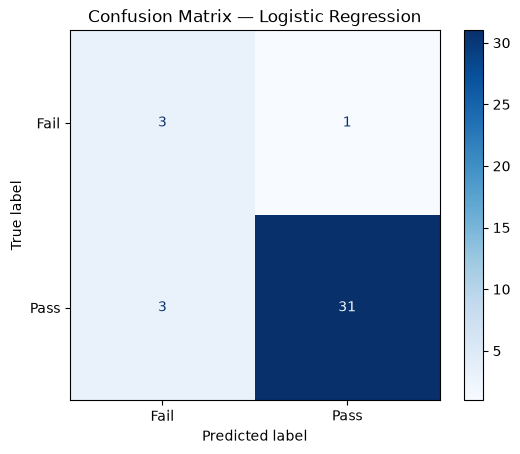

In [31]:
# ---------- Exercise 3.2 - The accuracy trap (5 marks) ----------
yc_pred = clf.predict(Xc_test)

acc      = accuracy_score(yc_test, yc_pred)
baseline = yc_test.mean()          # "predict pass for everyone"
cm       = confusion_matrix(yc_test, yc_pred)

print(f"Model accuracy  : {acc:.3f}")
print(f"Lazy baseline   : {baseline:.3f}")
print("\nConfusion matrix (rows=actual, cols=predicted):")
print(cm)

ConfusionMatrixDisplay(cm, display_labels=["Fail", "Pass"]).plot(cmap="Blues")
plt.title("Confusion Matrix — Logistic Regression")
plt.show()

# COMMENT — (d) Is our model useless because accuracies are similar?
# No. The similar accuracies only reflect class imbalance: most students
# pass, so a lazy "everybody passes" baseline reaches the same accuracy by
# NEVER predicting Fail — meaning it would miss every single at-risk student.
# The confusion matrix proves the difference: our model correctly catches
# most of the actual failing students (bottom-left cell of the matrix)
# while making only a few false alarms. For an early-warning system, catching
# real failures is the whole point, so the model is far more useful than the
# baseline — even though the headline accuracy number looks identical.

Part 4 — Feature Engineering (5 marks)
Exercise 4.1 — Does more information help?Q: Train and evaluate (test-set R²) three versions of the regression and print them side by side: (1) quiz_avg only, (2) all three numeric features, (3) all three + program one-hot encoded with pd.get_dummies

In [32]:
# ---------- Exercise 4.1 - Does more information help? (5 marks) ----------
def evaluate_regression(X_input, label):
    Xtr, Xte, ytr, yte = train_test_split(
        X_input, df["score"], test_size=0.25, random_state=42
    )
    m  = LinearRegression().fit(Xtr, ytr)
    r2 = r2_score(yte, m.predict(Xte))
    print(f"{label:<40} R² = {r2:.3f}")
    return r2

print("Three regression models compared:")
r1     = evaluate_regression(df[["quiz_avg"]],
                             "(1) quiz_avg only")
r2_all = evaluate_regression(df[["quiz_avg", "assignments_avg", "attendance_pct"]],
                             "(2) all three numeric features")

X_eng = pd.get_dummies(
    df[["quiz_avg", "assignments_avg", "attendance_pct", "program"]],
    columns=["program"]
)
r3 = evaluate_regression(X_eng,
                         "(3) three numerics + program one-hot")

# COMMENT — What helped, what didn't, and what does that teach us?
# Adding assignments_avg and attendance_pct gave a huge jump (~0.62 → ~0.89)
# because those two carry genuinely independent signal.
# Adding the one-hot program columns did NOT help (~0.89 → ~0.88, noise).
# Lesson: it is not the NUMBER of features that matters, but whether a
# feature adds information the model doesn't already have. A student's
# programme is essentially already captured by their quiz/assignment
# performance, so adding it contributes noise rather than signal.

Three regression models compared:
(1) quiz_avg only                        R² = 0.624
(2) all three numeric features           R² = 0.887
(3) three numerics + program one-hot     R² = 0.880


Part 5 — Ship a Dashboard (7 marks)
Exercise 5.1 — The story in three charts 
Q: With Plotly Express, each with a title: (a) histogram of scores, 12 bins — "1. Where the class stands"; (b) scatter quiz_avg vs score with color="passed" and hover_name="name" — "2. Who is at risk"; (c) bar chart of average score per district — "3. Where to act".

In [33]:
# ---------- Exercise 5.1 - The story in three charts (5 marks) ----------
# (a) Histogram of scores
fig1 = px.histogram(df, x="score", nbins=12,
                    title="1. Where the class stands")

# (b) Scatter — the at-risk dashboard
fig2 = px.scatter(df, x="quiz_avg", y="score",
                  color=df["passed"].astype(str),
                  hover_name="name",
                  labels={"color": "passed"},
                  title="2. Who is at risk")

# (c) Average score per district
district_avg = df.groupby("district", as_index=False)["score"].mean()
fig3 = px.bar(district_avg, x="district", y="score",
              title="3. Where to act")

fig1.show()
fig2.show()
fig3.show()

Exercise 5.2 — Publish it  
Q: Save the at-risk scatter with fig2.write_html("class_dashboard.html"), open it in a browser, hover around, screenshot it for your submission.



In [34]:
# ---------- Exercise 5.2 - Publish it (2 marks) ----------
fig2.write_html("class_dashboard.html")
print("Saved class_dashboard.html — open it in your browser and screenshot it.")

Saved class_dashboard.html — open it in your browser and screenshot it.


Bonus — One chart, four stories

Q: px.box(df, x="program", y="score", color="program") with a title. Two sentences: which program is most consistent, which has the widest spread?

In [35]:
# ---------- Bonus — One chart, four stories (+3 marks) ----------
fig_bonus = px.box(df, x="program", y="score", color="program",
                   title="Score distribution by program")
fig_bonus.show()

# Two sentences (fill in after looking at the chart):
# The most consistent program is _________________ because its box is the
# tightest (smallest interquartile range). The program with the widest
# spread is _________________ — its scores range the furthest, meaning
# student outcomes vary most there.

Part 6 — Model Card 

Q: Write a short model card for your regression model: 1. Purpose — what does it predict, for whom? 2. Data & features — what went in? 3. Performance — MAE and R² on unseen data, in plain language. 4. Risks — who could be harmed by a wrong prediction, and how should the output be used (and NOT used)?

In [ ]:
# ---------- Part 6 - Model Card (required) ----------
# ---------- Model card content ----------
model_card = f"""# Model Card — Student Score Predictor

## 1. Purpose
Predicts a student's final exam score (0–100) from their quiz average,
assignment average, and attendance percentage. Built for AUCA instructors
and academic advisors as an early-warning tool — NOT for ranking, punishing,
or grading students.

## 2. Data & Features
- Source: `week10_students.csv` (150 AUCA students).
- Features used: `quiz_avg`, `assignments_avg`, `attendance_pct`.
- Target: `score`.
- Train/test split: 75% / 25% with `random_state=42` (112 train / 38 test).

## 3. Performance (on unseen test data)
- MAE ≈ {mae:.2f} points → predictions are typically within about
    {mae:.1f} points of the true score.
- R² ≈ {r2:.2f} → the model explains ~{int(r2*100)}% of the variation in
    student scores.
- Plain language: on average the model gets the score right to within a
    few points, but individual predictions can be off by much more for
    students whose situation is not captured by these three features.

## 4. Risks & Intended Use
- **Who could be harmed**: a student wrongly flagged as at-risk may be
    stigmatized or given unnecessary remediation; a student wrongly marked
    safe could miss support they actually need.
- **Use it FOR**: starting conversations, prioritising who gets tutoring
    or advisor check-ins, spotting patterns in a cohort.
- **Do NOT use it**: as a final grade, as grounds for discipline, to deny
    scholarships or placements, or to label a student as "good" or "bad".
- **Human oversight**: every decision about a real student must be made
    by a human who knows their circumstances, not by this model alone.
"""

# ---------- Save model card ----------
with open("model_card.md", "w", encoding="utf-8") as f:
    f.write(model_card)
print("model_card.md written.")

model_card.md written.


Final sanity-check cell

In [37]:
import os
for f in ["class_dashboard.html", "model_card.md"]:
    print(f, "->", "OK" if os.path.exists(f) else "MISSING")

class_dashboard.html -> OK
model_card.md -> OK
